# Activity: Should We Trust the Alarm? — FreshKart Cold-Chain Case

**Unit 4 · AI-Assisted Visualization · AI-Assisted Pattern and Anomaly Visualization**
Visualization of Data, Understanding and Interpretation (UE24CS342AA9)

---

## The case

FreshKart's dark stores keep frozen food in **8 freezers** (one per store in Bengaluru, Pune and Hyderabad). Each freezer reports its temperature every hour. Last month FreshKart bought **ColdSense**, an AI service that scores every reading for "anomaly" and raises an alert when the score is **≥ 0.5**.

Cold-chain lead **Ravi** has six weeks of readings, the ColdSense scores, and the **maintenance log** (what technicians actually found). His technicians are tired of being sent out at night. He asks:

> *"Is ColdSense's alert feed trustworthy? Which alerts should my team chase, and what is it missing?"*

**You are the analyst.** Use the data and the visualizations to verify, correct or reject what the vendor claims.

**Ground rules (from the lecture):** an AI score is a *derived attribute*: look at it, don't only threshold it · flags are **candidates, not conclusions** · report precision and recall, not accuracy · scale emphasis to confidence.

**How to work:** run the notebook top to bottom. Complete every cell marked `# TODO` (replace `None` with your code or answer) and write in the cells marked **✏️ Your answer**. Cells that depend on your TODO will tell you if something is still missing.

### The data: `freshkart_coldchain.csv` (synthetic)

| Column | Meaning |
|---|---|
| `timestamp` | hour of the reading (1 Aug – 11 Sep 2026) |
| `city`, `store_id`, `freezer_id` | where the freezer is |
| `temp_c` | freezer temperature (°C); normal is about −18 °C |
| `door_opens` | number of door openings in that hour (busy by day, quiet at night) |
| `compressor_kw` | compressor power draw (kW) |
| `ai_score`, `ai_flag` | ColdSense anomaly score (0–1) and alert (1 if score ≥ 0.5) |
| `confirmed_fault`, `fault_type` | from the maintenance log: 1 if technicians confirmed a real fault in that hour, and what it was |

**Domain note from the maintenance team:** every freezer runs an automatic **defrost cycle from 02:00 to 04:00** each night. The heater warms the coil, so the temperature rises for those two hours. That is normal.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (6, 3.2), "axes.spines.top": False, "axes.spines.right": False})
GREY, ACCENT, BLUE = "#bdbdbd", "#d95f02", "#4c78a8"

def ready(*vals):
    """Helper: tells you if a TODO above is still unanswered."""
    ok = all(v is not None for v in vals)
    if not ok:
        print("⚠ Complete the TODO cell(s) above first, then re-run this cell.")
    return ok

df = pd.read_csv("freshkart_coldchain.csv", parse_dates=["timestamp"])
df["hour"] = df["timestamp"].dt.hour
df.head()

,timestamp,city,store_id,freezer_id,temp_c,door_opens,compressor_kw,ai_score,ai_flag,confirmed_fault,fault_type,hour
0,2026-08-01,Bengaluru,B1,FZ-B1,-18.1,0,1.29,0.000,0,0,NaN,0
1,2026-08-01,Bengaluru,B2,FZ-B2,-18.7,0,1.16,0.000,0,0,NaN,0
2,2026-08-01,Bengaluru,B3,FZ-B3,-17.7,0,1.21,0.000,0,0,NaN,0
3,2026-08-01,Hyderabad,H1,FZ-H1,-17.8,0,1.30,0.037,0,0,NaN,0
4,2026-08-01,Hyderabad,H2,FZ-H2,-18.2,0,1.32,0.035,0,0,NaN,0


## ColdSense's monthly report (to be validated)

| # | Vendor statement |
|---|---|
| 1 | "ColdSense is **97.9% accurate**, so its alerts can be trusted." |
| 2 | "**Most faults happen around 2 am.** We recommend a night technician." |
| 3 | "**All 10 compressor trips** in the period were caught." |
| 4 | "Freezer **FZ-H2 ran without a single fault** in August." |
| 5 | "A reading of **−14 °C is abnormal** for any freezer, at any time." |
| 6 | "An alert with a score of **0.92 means a 92% chance** of a real fault." |
| 7 | "The **default threshold of 0.5** is the best setting for FreshKart." |
| 8 | "A new FZ-B1 reading of **−15.9 °C at 14:00** is **15 standard errors** above normal: a definite fault." |

---
## Part 1 · Data abstraction: items, attributes and derived attributes

Munzner: before choosing a view, ask what the **items** and **attributes** are. The AI does not change the items; it **derives** new attributes.

In [2]:
derived_cols = ["ai_score", "ai_flag"]        # TODO: list the column(s) that ColdSense derived (not measured by the freezer or written by technicians)
n_alerts = int((df["ai_flag"] == 1).sum())            # TODO: number of rows with an alert (ai_flag == 1)
fault_rate_pct = round(df["confirmed_fault"].mean() * 100, 2)      # TODO: % of rows that are confirmed faults, 2 decimals (this is the base rate)

if ready(derived_cols, n_alerts, fault_rate_pct):
    print(f"derived: {derived_cols} | alerts: {n_alerts} | faults: {df.confirmed_fault.sum()} of {len(df)} rows ({fault_rate_pct}%)")
    display(df[df.confirmed_fault == 1].groupby("fault_type").size().rename("fault hours"))

derived: ['ai_score', 'ai_flag'] | alerts: 159 | faults: 46 of 8064 rows (0.57%)


fault_type
compressor trip         10
defrost heater stuck    11
sensor frozen           25
Name: fault hours, dtype: int64

**✏️ Your answer (Part 1):** `ai_score` is quantitative and `ai_flag` is binary. Which **visual channel** suits each, and what information does the flag throw away that the score keeps?

*Your answer:*

`ai_score` is a quantitative (ordered) attribute, so it needs a **magnitude channel**: best is position on a common scale (plot the score as its own line/strip under the temperature), or else a sequential luminance/saturation ramp or mark size. `ai_flag` is binary/categorical, so an **identity channel** is enough: a hue or a shape (filled vs hollow marker).

The flag throws away **how far** a reading is from the cut-off, i.e. the model's confidence. A score of 0.51 and a score of 1.00 both become "1", and 0.49 and 0.00 both become "0". With only the flag we cannot rank the 159 alerts, cannot see the 5 heater faults sitting just under 0.5 (scores 0.19–0.39), and cannot try another threshold.

---
## Part 2 · Distributions: bin width and the score distribution

### 2a · Temperature histogram

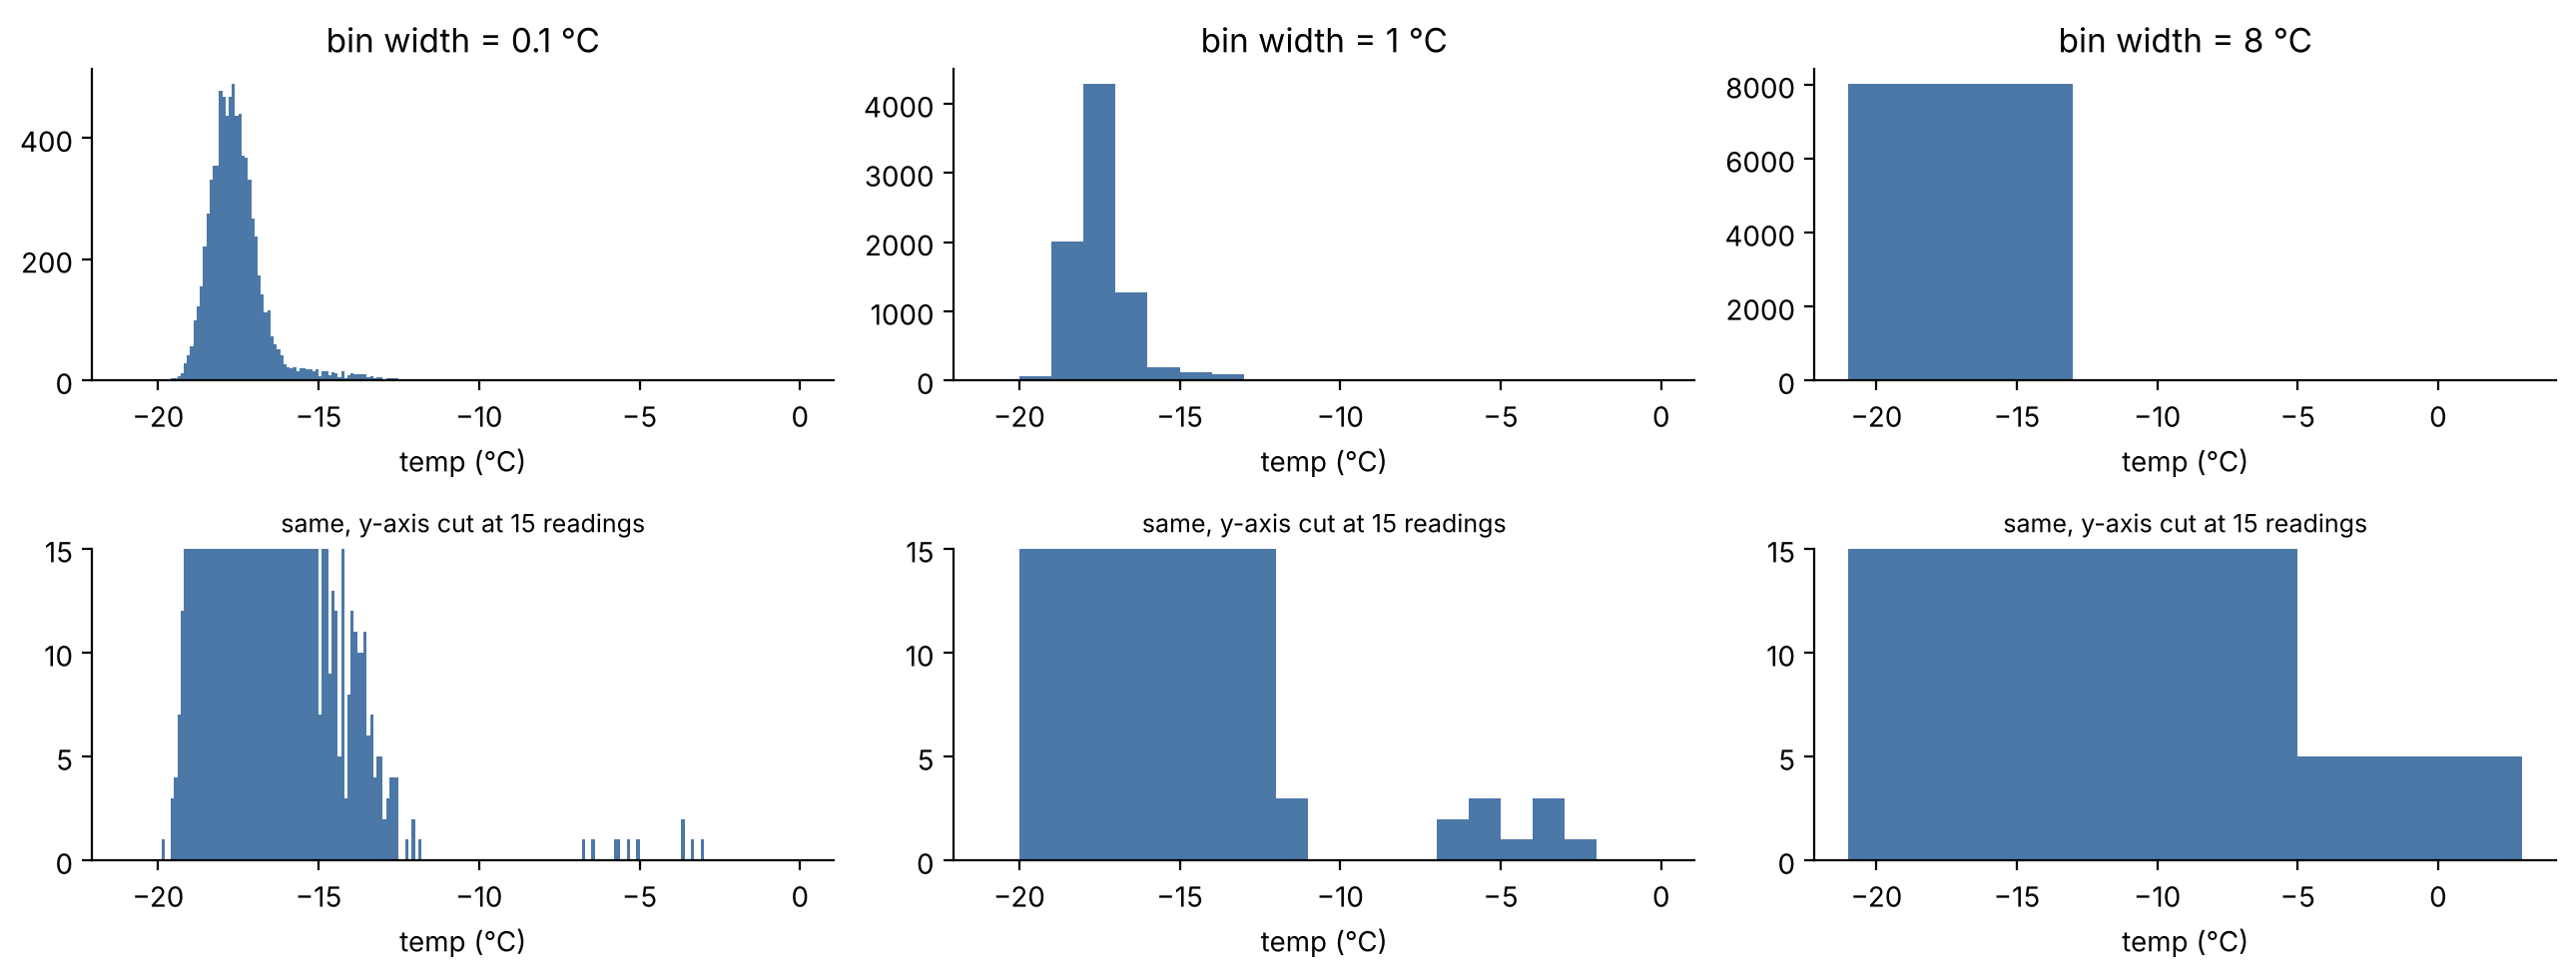

warm tail visible with bin widths [0.1, 1] | readings warmer than -8 °C: 10


In [3]:
fig, axes = plt.subplots(2, 3, figsize=(13, 5))
for col, w in enumerate([0.1, 1, 8]):
    for row, top in enumerate([None, 15]):
        ax = axes[row, col]
        ax.hist(df["temp_c"], bins=np.arange(-21, 0 + w, w), color=BLUE)
        if top: ax.set_ylim(0, top); ax.set_title(f"same, y-axis cut at {top} readings", fontsize=9)
        else: ax.set_title(f"bin width = {w} °C")
        ax.set_xlabel("temp (°C)")
plt.tight_layout(); plt.show()

warm_tail_visible_bins = [0.1, 1]   # TODO: in the bottom row, which bin width(s) show the very warm readings (above -8 °C) as a separate group? a list, e.g. [0.1]
n_warm_readings = int((df["temp_c"] > -8).sum())          # TODO: how many readings are warmer than -8 °C? (count them with code)
print(f"warm tail visible with bin widths {warm_tail_visible_bins} | readings warmer than -8 °C: {n_warm_readings}")

### 2b · Look at the AI scores before trusting the cut-off
Wilke: compare groups with overlapping densities, not stacked histograms.

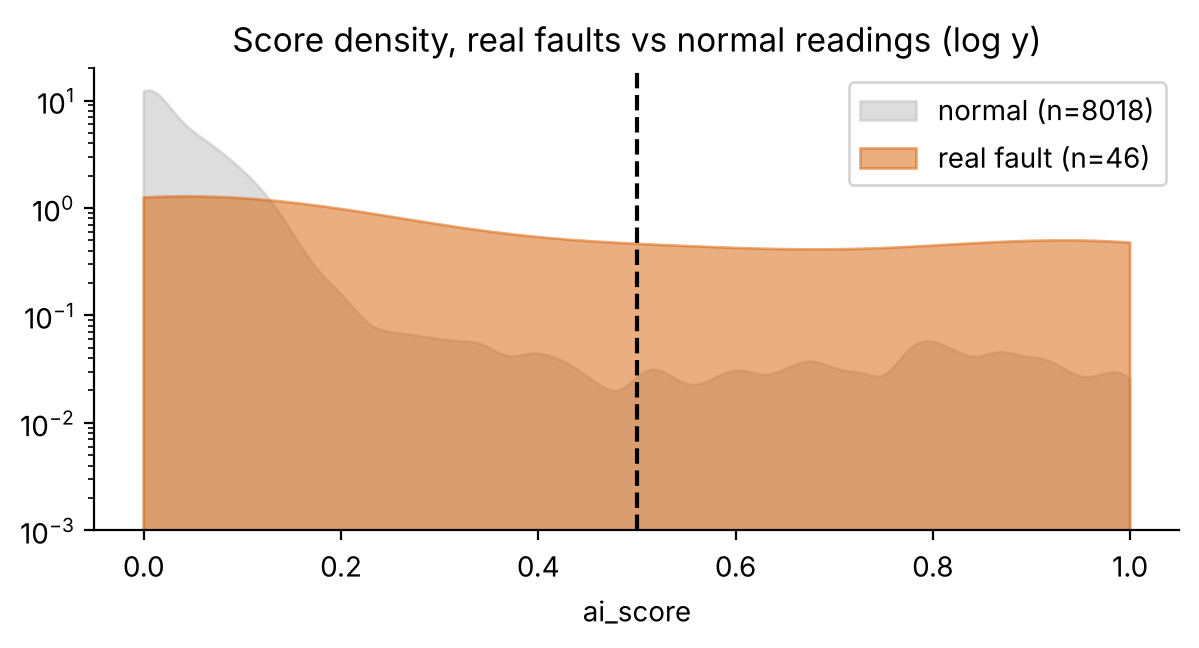

In [4]:
xs = np.linspace(0, 1, 300)
fig, ax = plt.subplots(figsize=(7, 3))
for lab, col in [(0, GREY), (1, ACCENT)]:
    s = df.loc[df.confirmed_fault == lab, "ai_score"]
    ax.fill_between(xs, stats.gaussian_kde(s)(xs), color=col, alpha=.5, label=f"{'real fault' if lab else 'normal'} (n={len(s)})")
ax.axvline(0.5, color="k", ls="--"); ax.set_yscale("log"); ax.set_ylim(1e-3, 20)
ax.set_xlabel("ai_score"); ax.legend(); ax.set_title("Score density, real faults vs normal readings (log y)")
plt.show()

scores_separate_faults = False   # TODO: True/False - is there a clean score cut-off that separates real faults from normal readings?

**✏️ Your answer (Part 2):** Why is a histogram "a parameterised algorithm", and what would you tell a colleague who says *"the 8 °C histogram shows no anomalies"*?

*Your answer:*

A histogram is not the raw data: it is the output of a counting algorithm whose **parameters** (bin width, bin origin, and here also the y-axis limit) are chosen by the analyst or by a software default. Change the parameters and the picture changes, although the data does not.

To the colleague: "The 8 °C histogram *cannot* show anomalies. There are only 10 readings warmer than −8 °C out of 8,064 (all 10 are compressor trips at −3 to −7 °C). With 8 °C bins, half of them are merged into the same bar as normal defrost readings and the rest are a 5-count bar next to a bar of 8,028, which is invisible on that y-axis. Use 0.1 or 1 °C bins and zoom the y-axis (cut at 15): the warm group then stands apart with a clear gap between about −12 and −7 °C. An empty-looking chart is not evidence of absence; check the bin width and the axis first."

The score density (2b) says the same thing about the AI: the two distributions overlap, with many real faults scored near 0 and many normal readings scored above 0.5, so no single cut-off separates them.

---
## Part 3 · Outlier rules on a short window (vendor statement 3)

Ten consecutive readings from **FZ-P1**, 12 Aug 06:00–15:00. One of them is a compressor trip.

In [5]:
window = df[(df.freezer_id == "FZ-P1") & (df.timestamp >= "2026-08-12 06:00") & (df.timestamp < "2026-08-12 16:00")]
v = window["temp_c"].values
print(window[["timestamp", "temp_c", "fault_type"]].to_string(index=False))

z_max = np.abs((v - v.mean()) / np.std(v, ddof=1)).max()          # TODO: the largest |z| in v, using the sample SD (hint: np.std(v, ddof=1))
q1, q3 = np.percentile(v, [25, 75])
upper_fence = q3 + 1.5 * (q3 - q1)    # TODO: Q3 + 1.5 * IQR

if ready(z_max, upper_fence):
    print(f"largest |z| = {z_max:.2f} -> flagged by |z| > 3? {z_max > 3}")
    print(f"upper IQR fence = {upper_fence:.2f} °C -> trip flagged by IQR rule? {v.max() > upper_fence}")
    print(f"largest |z| possible with n = {len(v)}: {(len(v) - 1) / np.sqrt(len(v)):.2f}")

          timestamp  temp_c      fault_type
2026-08-12 06:00:00   -17.5             NaN
2026-08-12 07:00:00   -18.2             NaN
2026-08-12 08:00:00   -17.4             NaN
2026-08-12 09:00:00   -17.7             NaN
2026-08-12 10:00:00   -16.6             NaN
2026-08-12 11:00:00    -3.6 compressor trip
2026-08-12 12:00:00   -17.0             NaN
2026-08-12 13:00:00   -16.8             NaN
2026-08-12 14:00:00   -17.7             NaN
2026-08-12 15:00:00   -17.7             NaN
largest |z| = 2.83 -> flagged by |z| > 3? False
upper IQR fence = -15.58 °C -> trip flagged by IQR rule? True
largest |z| possible with n = 10: 2.85


**✏️ Your answer (Part 3):** Explain in two sentences why the z-score rule missed the trip here (use the word *masking*) and why the IQR rule did not.

*Your answer:*

The trip (−3.6 °C) is itself part of the 10 readings used to compute the mean and SD, so it pulls the mean up and inflates the SD, and this **masking** hides it from its own test: its z is only 2.83, and with n = 10 no value can ever exceed |z| = 2.85, so the "|z| > 3" rule can never fire on this window. The IQR rule is built from the quartiles, which a single extreme value barely moves, so the fence stays at −15.6 °C and the −3.6 °C trip is flagged easily.

---
## Part 4 · How good is ColdSense? (vendor statement 1)

In [6]:
flag = df.ai_flag == 1
real = df.confirmed_fault == 1

TP = int((flag & real).sum())    # TODO: alerts that were real faults
FP = int((flag & ~real).sum())    # TODO: alerts on normal readings (false alarms)
FN = int((~flag & real).sum())    # TODO: real faults with no alert (missed)
TN = int((~flag & ~real).sum())    # TODO: normal readings with no alert

if ready(TP, FP, FN, TN):
    display(pd.DataFrame([[TP, FN], [FP, TN]], index=["real fault", "normal"], columns=["alert", "no alert"]))

,alert,no alert
real fault,16,30
normal,143,7875


In [7]:
precision = TP / (TP + FP)              # TODO
recall = TP / (TP + FN)                 # TODO
f1 = 2 * precision * recall / (precision + recall)                     # TODO
accuracy = (TP + TN) / (TP + FP + FN + TN)               # TODO
flag_nothing_accuracy = (TN + FP) / (TP + FP + FN + TN)  # TODO: accuracy of a "detector" that never raises an alert

if ready(precision, recall, f1, accuracy, flag_nothing_accuracy):
    print(f"precision = {precision:.2f} | recall = {recall:.2f} | F1 = {f1:.2f} | accuracy = {accuracy:.1%} | never-alert accuracy = {flag_nothing_accuracy:.1%}")

precision = 0.10 | recall = 0.35 | F1 = 0.16 | accuracy = 97.9% | never-alert accuracy = 99.4%


**✏️ Your answer (Part 4):** Rewrite vendor statement 1 so it is honest. Use precision and recall, and say in plain words what they mean for Ravi's technicians (how many call-outs are wasted, how many faults are missed).

*Your answer:*

Honest version of statement 1:

> "ColdSense agrees with the maintenance log on 97.9% of hourly readings, but only 0.57% of readings are faults, so a detector that **never** raises an alert would score 99.4%. Its **precision is 0.10** and its **recall is 0.35** (F1 = 0.16)."

In plain words for Ravi: of 159 alerts, only 16 were real, so about **9 out of every 10 call-outs are wasted trips** (143 false alarms). And of the 46 fault-hours the technicians confirmed, ColdSense alerted on only 16, so it **misses about 2 out of every 3** (30 missed). The 97.9% comes almost entirely from the 7,875 normal readings it correctly left alone, which says nothing about whether an alert can be trusted.

---
## Part 5 · Thresholds and costs (vendor statement 7)

A missed fault can spoil a freezer of stock (cost ≈ **40** units); a false call-out costs **1** unit of technician time.

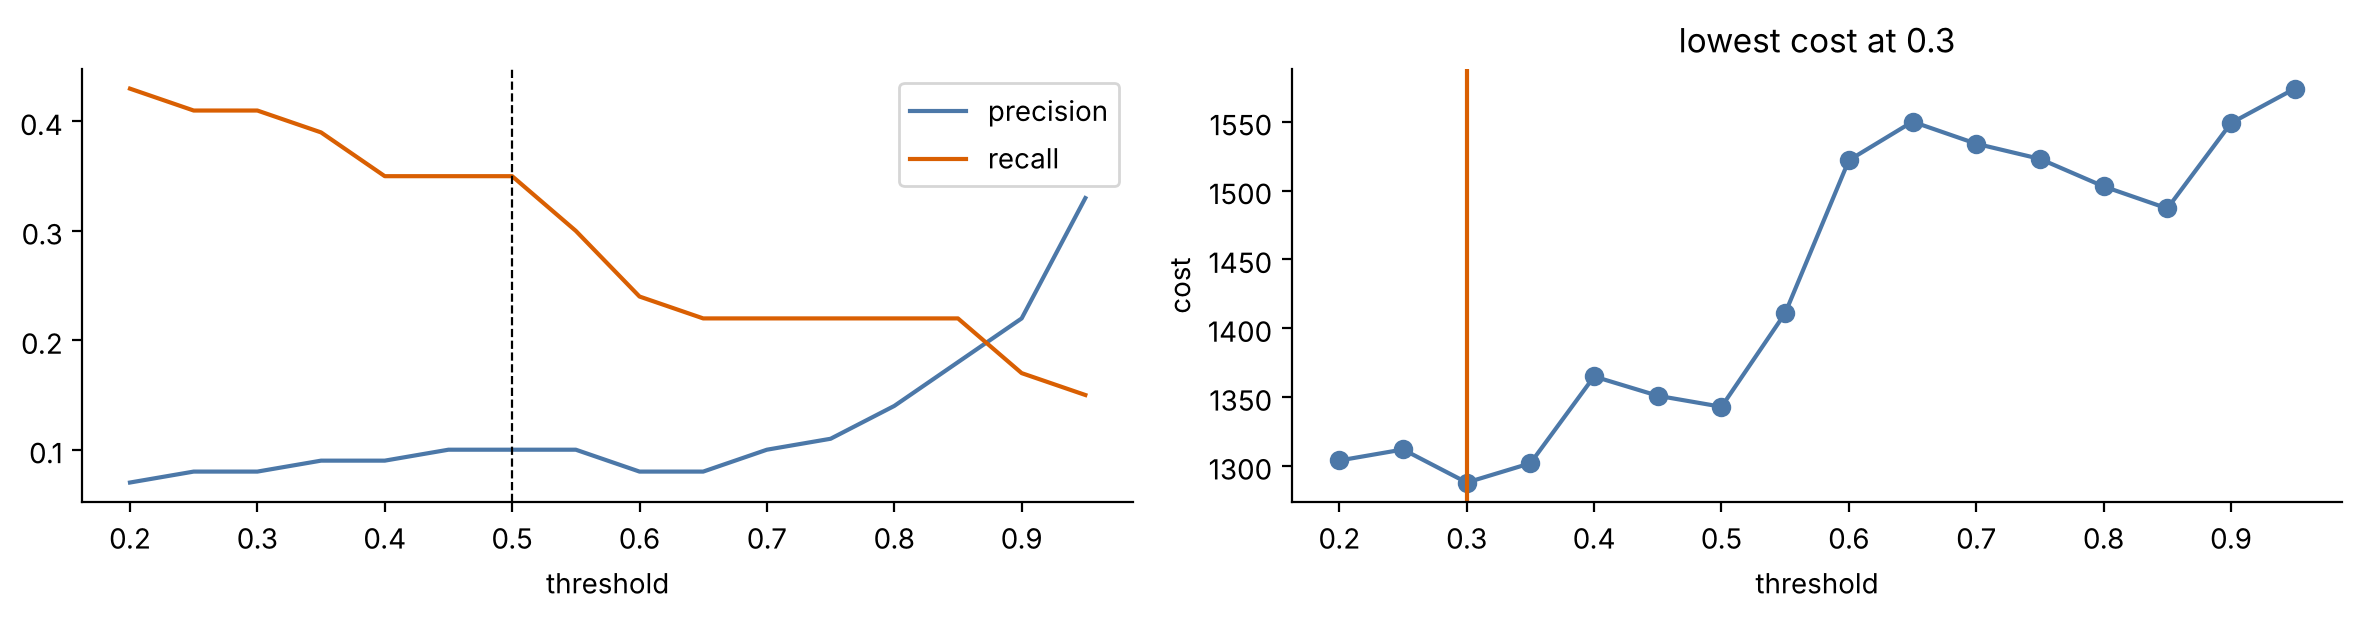

,threshold,TP,FP,FN,precision,recall,cost
0,0.20,20,264,26,0.07,0.43,1304
1,0.25,19,232,27,0.08,0.41,1312
2,0.30,19,208,27,0.08,0.41,1288
3,0.35,18,182,28,0.09,0.39,1302
4,0.40,16,165,30,0.09,0.35,1365
5,0.45,16,151,30,0.10,0.35,1351
6,0.50,16,143,30,0.10,0.35,1343
7,0.55,14,131,32,0.10,0.30,1411
8,0.60,11,122,35,0.08,0.24,1522
9,0.65,10,110,36,0.08,0.22,1550


In [8]:
grid = np.round(np.arange(0.20, 0.96, 0.05), 2)
sweep = pd.DataFrame({"threshold": grid})
sweep["TP"] = [((df.ai_score >= g) & real).sum() for g in grid]
sweep["FP"] = [((df.ai_score >= g) & ~real).sum() for g in grid]
sweep["FN"] = real.sum() - sweep["TP"]
sweep["precision"] = (sweep.TP / (sweep.TP + sweep.FP)).round(2)
sweep["recall"] = (sweep.TP / real.sum()).round(2)

sweep["cost"] = 40 * sweep["FN"] + 1 * sweep["FP"]          # TODO: 40 * FN + 1 * FP
best_threshold = sweep.loc[sweep["cost"].astype(float).idxmin(), "threshold"]         # TODO: the threshold with the lowest cost (hint: sweep.loc[sweep["cost"].astype(float).idxmin(), "threshold"])

if ready(best_threshold) and sweep["cost"].notna().all():
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))
    ax[0].plot(sweep.threshold, sweep.precision, color=BLUE, label="precision"); ax[0].plot(sweep.threshold, sweep.recall, color=ACCENT, label="recall")
    ax[0].axvline(0.5, color="k", ls="--", lw=.8); ax[0].legend(); ax[0].set_xlabel("threshold")
    ax[1].plot(sweep.threshold, sweep.cost.astype(float), color=BLUE, marker="o"); ax[1].axvline(best_threshold, color=ACCENT)
    ax[1].set_xlabel("threshold"); ax[1].set_ylabel("cost"); ax[1].set_title(f"lowest cost at {best_threshold}")
    plt.tight_layout(); plt.show()
    display(sweep)

**✏️ Your answer (Part 5):** Even at the best threshold, recall stays low. Why can no threshold fix this detector? (Hint: look at *which* faults are never scored high.)

*Your answer:*

The lowest cost is at a threshold of **0.30** (cost 1,288 vs 1,343 at the vendor's 0.5), so 0.5 is not the best setting. But the gain is tiny and recall only moves from 0.35 to 0.41, because the threshold can only re-cut the scores the model already gave.

The problem is in the scores, not the cut-off. All 25 **sensor-frozen** hours have scores between 0.00 and 0.10: a reading stuck at exactly −18.0 °C looks perfectly normal one reading at a time, so it sits below every threshold on the grid. Five of the 11 **defrost-heater-stuck** hours are scored 0.19–0.39. To catch the frozen-sensor hours we would have to drop the threshold under 0.1, where almost every normal reading would also be flagged. Meanwhile the 143 normal 02:00 defrost readings score *above* 0.5, many above 0.9. Lowering the threshold buys false alarms, raising it loses heater faults, and no value reaches the frozen sensor. The detector needs different inputs (hour-of-day context, behaviour over a window), not a different threshold.

---
## Part 6 · Where do the errors come from?

### 6a · When do the false alarms happen? (vendor statement 2)

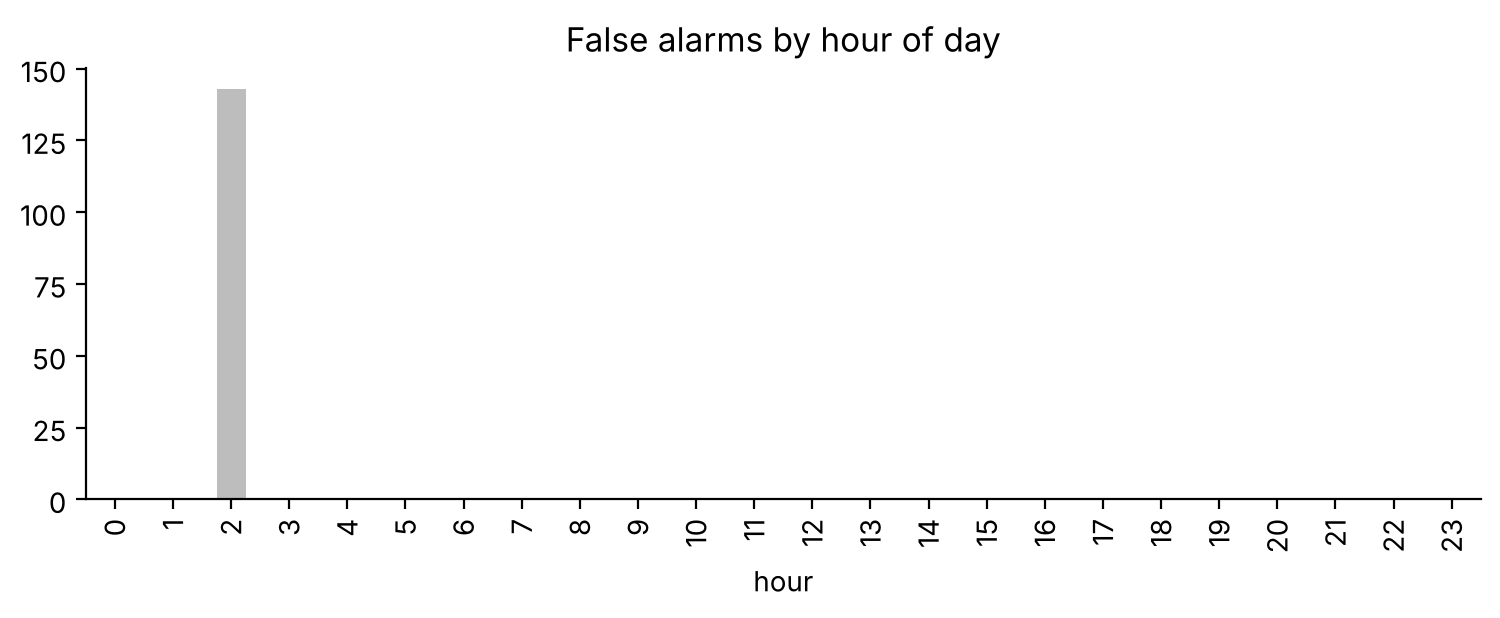

100% of false alarms happen at 2:00


In [9]:
fp_rows = df[flag & ~real]
fp_rows.groupby("hour").size().reindex(range(24), fill_value=0).plot.bar(color=GREY, title="False alarms by hour of day", figsize=(9, 2.8))
plt.show()

fp_peak_hour = int(fp_rows.groupby("hour").size().idxmax())          # TODO: the hour with the most false alarms (an int)
fp_share_at_peak = (fp_rows["hour"] == fp_peak_hour).mean()      # TODO: share of all false alarms that fall in that hour (0-1)

if ready(fp_peak_hour, fp_share_at_peak):
    print(f"{fp_share_at_peak:.0%} of false alarms happen at {fp_peak_hour}:00")

### 6b · Which faults does ColdSense miss?

In [10]:
caught = df[real].groupby("fault_type")["ai_flag"].agg(caught="sum", fault_hours="size")
caught["recall"] = (caught.caught / caught.fault_hours).round(2)
display(caught)

never_caught_type = caught.index[caught["caught"] == 0][0]     # TODO: the fault type ColdSense never catches
anomaly_kind = 'collective'          # TODO: is that a 'point', 'contextual' or 'collective' anomaly?
print(f"never caught: {never_caught_type} -> a {anomaly_kind} anomaly")

,caught,fault_hours,recall
fault_type,,,
compressor trip,10,10,1.00
defrost heater stuck,6,11,0.55
sensor frozen,0,25,0.00


never caught: sensor frozen -> a collective anomaly


### 6c · Contextual anomalies: compare each reading with its own hour

A **context-aware** baseline compares each reading with the same freezer at the same hour of day (median and MAD over the six weeks).

In [11]:
grp = df.groupby(["freezer_id", "hour"])["temp_c"]
df["hour_median"] = grp.transform("median")
df["hour_mad"] = grp.transform(lambda s: 1.4826 * stats.median_abs_deviation(s))

df["z_context"] = (df["temp_c"] - df["hour_median"]) / df["hour_mad"]       # TODO: (temp_c - hour_median) / hour_mad

if ready(*df["z_context"].head(1)):
    ctx_flag = df["z_context"].astype(float) > 4
    found = df[real & ctx_flag & ~flag]
    print(f"Real faults the context baseline catches but ColdSense missed: {len(found)}")
    display(found[["timestamp", "freezer_id", "temp_c", "hour_median", "z_context", "ai_score", "fault_type"]])
    print(f"False alarms at 02:00 under the context baseline: {(ctx_flag & ~real & (df.hour == 2)).sum()} (ColdSense: {(flag & ~real & (df.hour == 2)).sum()})")

Real faults the context baseline catches but ColdSense missed: 3


,timestamp,freezer_id,temp_c,hour_median,z_context,ai_score,fault_type
1279,2026-08-07 15:00:00,FZ-P2,-14.6,-17.50,4.890058,0.369,defrost heater stuck
4731,2026-08-25 15:00:00,FZ-H1,-14.8,-17.50,6.070417,0.388,defrost heater stuck
6273,2026-09-02 16:00:00,FZ-B2,-15.2,-17.35,4.143300,0.189,defrost heater stuck


False alarms at 02:00 under the context baseline: 0 (ColdSense: 143)


### 6d · Collective anomalies: a run of readings that is abnormal together

                           min                 max  count
freezer_id                                               
FZ-H2      2026-08-20 14:00:00 2026-08-20 22:00:00      9
FZ-P1      2026-09-06 12:00:00 2026-09-06 17:00:00      6


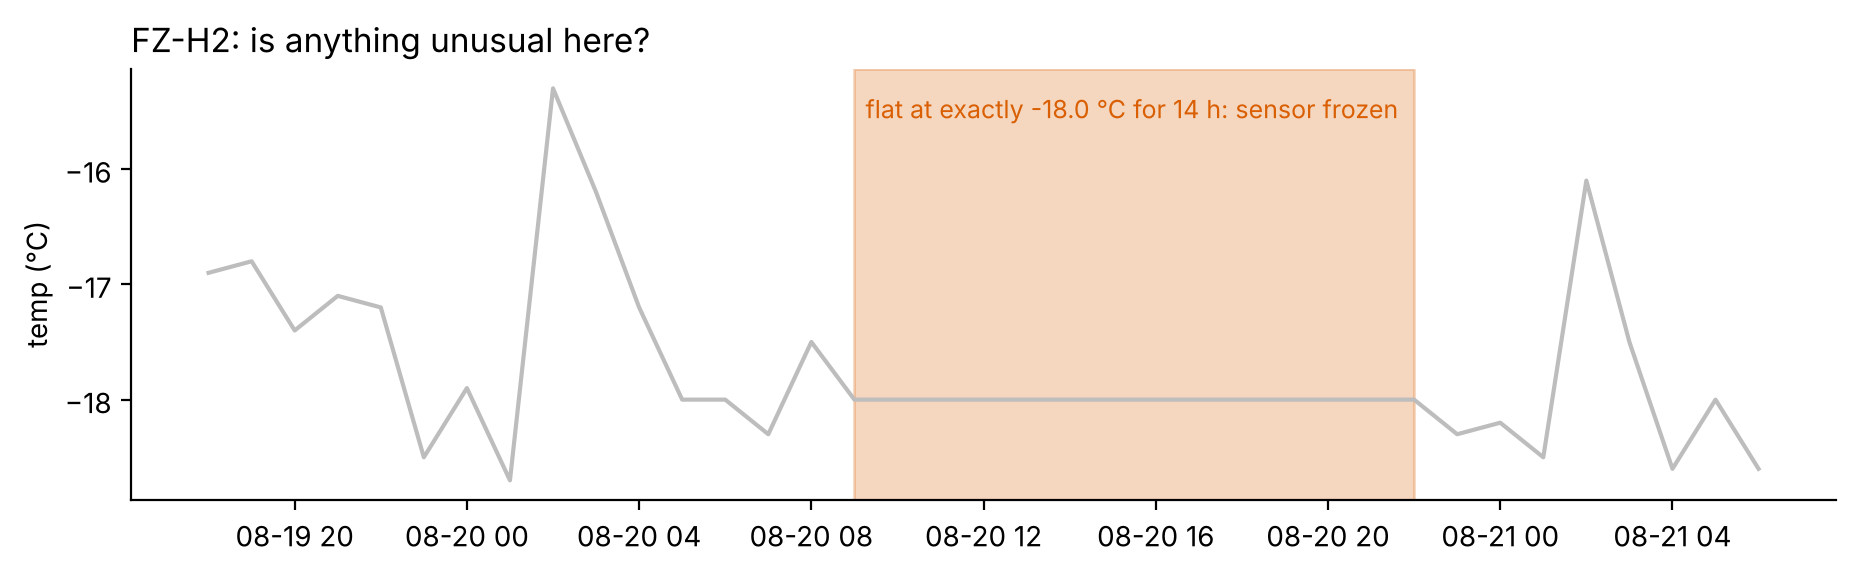

In [12]:
df = df.sort_values(["freezer_id", "timestamp"])
df["roll_sd_6h"] = df.groupby("freezer_id")["temp_c"].transform(lambda s: s.rolling(6).std())

flat = df[df["roll_sd_6h"] < 0.01]   # TODO: rows where the 6-hour rolling SD is (almost) zero, e.g. df[df["roll_sd_6h"] < 0.01]

if ready(flat):
    print(flat.groupby("freezer_id")["timestamp"].agg(["min", "max", "count"]))
    h2 = df[(df.freezer_id == "FZ-H2") & (df.timestamp.between("2026-08-19 18:00", "2026-08-21 06:00"))]
    fig, ax = plt.subplots(figsize=(11, 2.8))
    ax.plot(h2.timestamp, h2.temp_c, color=GREY)
    # TODO (drawing): highlight the WHOLE flat span on this chart, not single points (hint: ax.axvspan(start, end, color=ACCENT, alpha=.25))
    flat_h2 = flat[flat.freezer_id == "FZ-H2"]
    span_start = flat_h2["timestamp"].min() - pd.Timedelta(hours=5)   # a 6-hour rolling SD only reaches zero at the 6th flat reading, so the run began 5 h earlier
    span_end = flat_h2["timestamp"].max()
    ax.axvspan(span_start, span_end, color=ACCENT, alpha=.25)
    ax.annotate(f"flat at exactly {flat_h2['temp_c'].iloc[0]:.1f} °C for {int((span_end - span_start) / pd.Timedelta(hours=1)) + 1} h: sensor frozen",
                xy=(span_start, h2.temp_c.max()), xytext=(4, -2), textcoords="offset points", va="top", color=ACCENT, fontsize=9)
    ax.set_ylabel("temp (°C)")

    ax.set_title("FZ-H2: is anything unusual here?", loc="left"); plt.show()
df = df.sort_values(["timestamp", "store_id"])

**✏️ Your answer (Part 6):**
(a) Rewrite vendor statement 2. What really happens at 2 am, and what would happen if FreshKart hired a night technician based on the vendor's report?
(b) Is vendor statement 5 true? Use the words *contextual anomaly* and say what a chart must show for a viewer to judge such an alert.
(c) What is wrong with vendor statement 4, and why can a detector that scores readings one at a time never catch this kind of fault?

*Your answer:*

**(a)** Rewrite of statement 2: "Most ColdSense **alerts** happen at 2 am, and every one of them is a false alarm. All 143 false alarms (100%) fall in the 02:00 hour; no confirmed fault occurred at 2 am. Confirmed faults happened between 07:00 and 22:00, mostly in the afternoon (peak 15:00–16:00)." What really happens at 2 am is the scheduled **defrost cycle** (02:00–04:00): the heater warms the coil and the temperature rises to about −14 °C, which is normal. The vendor counted its own alerts as if they were faults. A night technician hired on this report would be sent to healthy freezers night after night, would find nothing, and would not be on shift in the afternoon when the real faults occur; the team would also learn to ignore alerts.

**(b)** No. Statement 5 is false as written, because −14 °C is a **contextual anomaly**: the same value is normal in one context and a fault in another. At 02:00 the typical reading across freezers is about −14.7 °C (defrost), so −14 °C is ordinary; at 15:00 the typical reading is −17.5 °C, and −14 to −15 °C there is exactly what the confirmed "defrost heater stuck" faults look like. Comparing each reading with its own freezer and hour (6c) recovers 3 heater-fault hours ColdSense missed and raises **0** false alarms at 02:00 instead of 143. For a viewer to judge such an alert, the chart must show the **context, not just the point**: the expected band for that freezer at that hour of day (median ± a few MADs), the defrost window shaded, and the surrounding hours or previous days so the reading can be compared with what is normal *then*.

**(c)** Statement 4 is wrong: the maintenance log shows FZ-H2's **sensor was frozen** on 20 August, reporting exactly −18.0 °C for 14 consecutive hours (09:00–22:00). "No alert" was reported as "no fault". This is a **collective anomaly**: each individual reading (−18.0 °C) is the most normal value a freezer can show, so any detector that scores one reading at a time gives it a score near 0 (the highest was 0.10). The abnormal thing is the *run*: a real freezer never holds exactly the same value for hours, with no door-opening wobble and no 02:00-style variation. Only a feature computed over a window, such as the 6-hour rolling SD being zero, can see it. The same test also finds a second frozen-sensor episode on FZ-P1 on 6 September.

---
## Part 7 · Highlighting, saliency and frequency framing (vendor statement 6)

### 7a · Emphasis scaled to confidence
The vendor's dashboard paints every alert bright red. Implement the lecture's checklist: **≥ 0.90 strong**, **0.70–0.90 moderate**, **0.50–0.70 subtle outline**, **below 0.50 no emphasis** (the data stays visible).

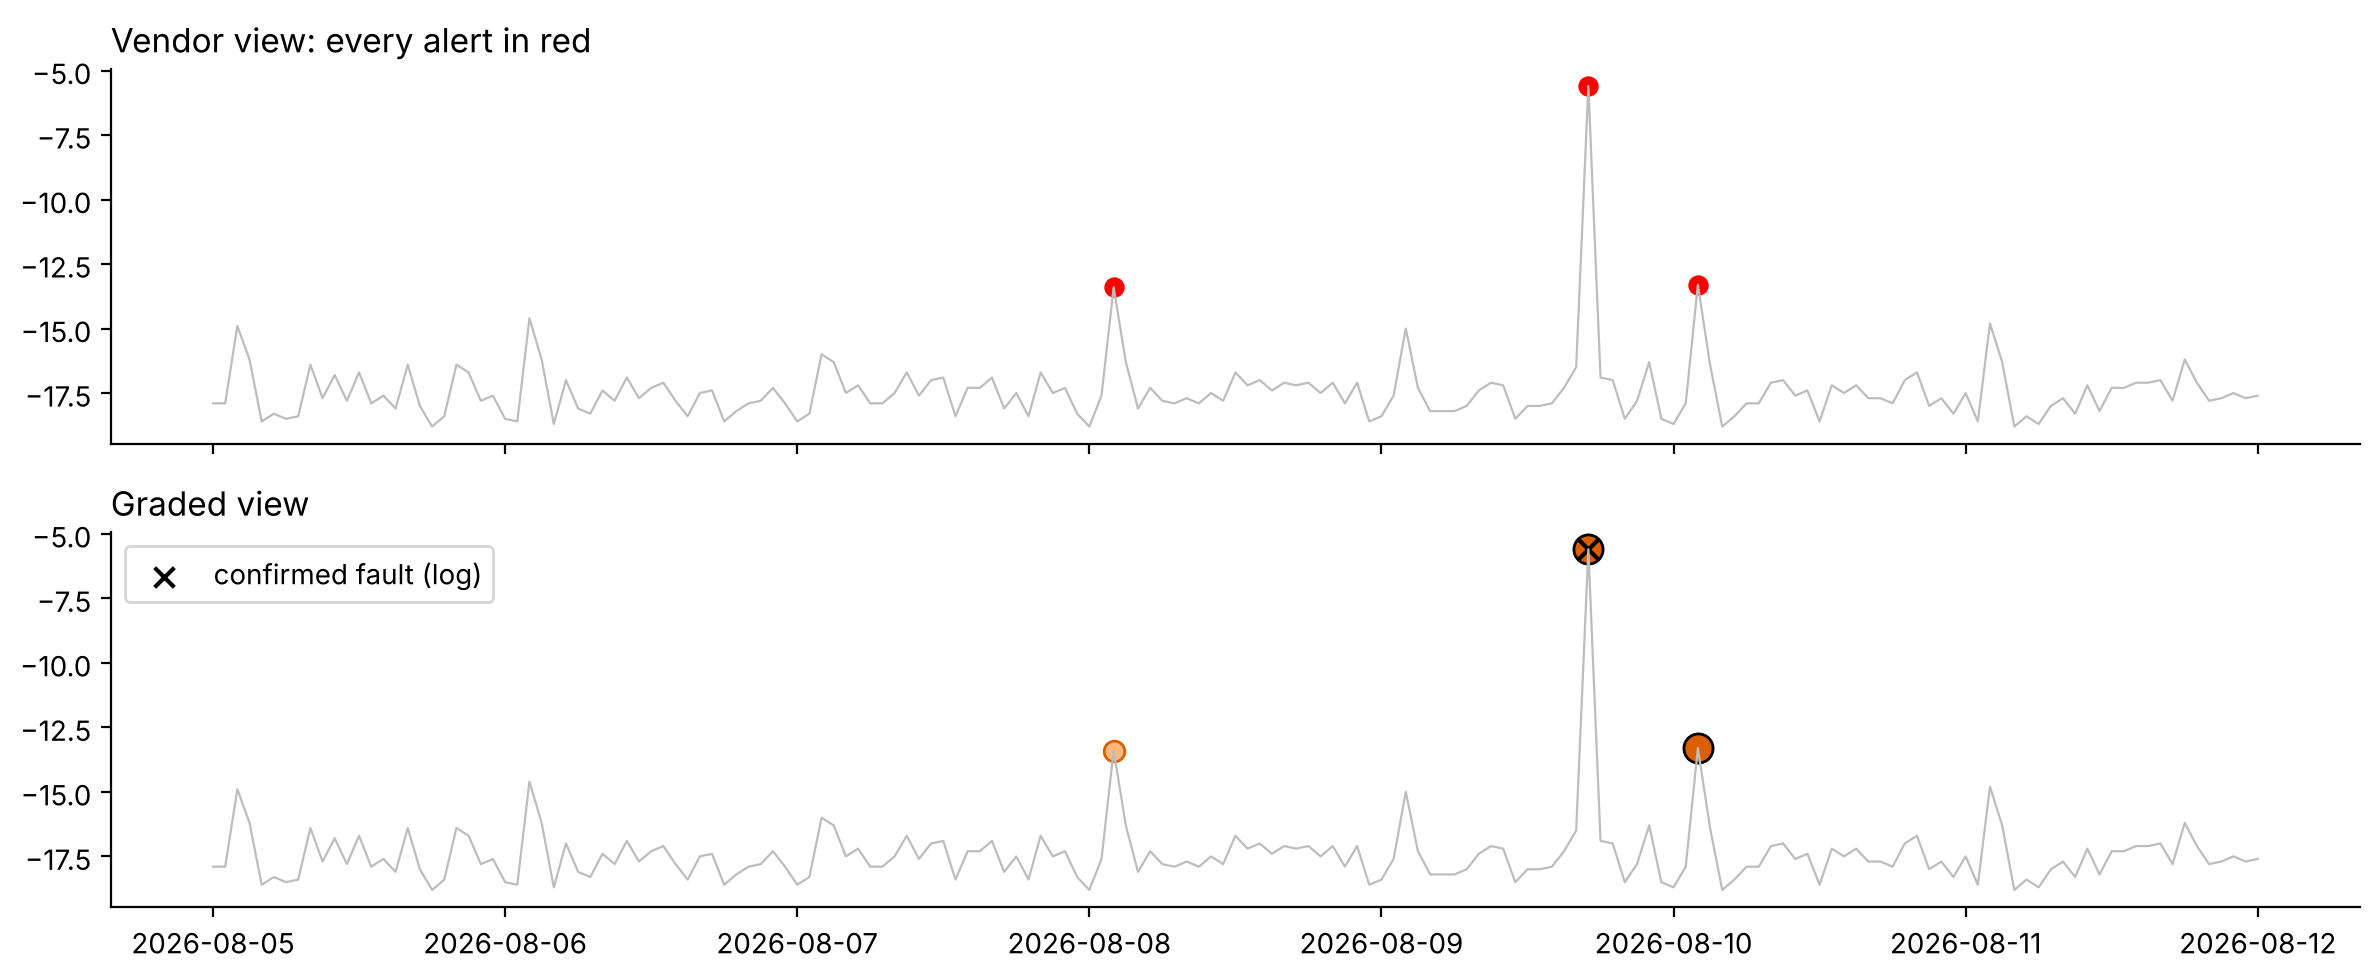

In [13]:
def emphasis(score):
    """Return (colour, marker size, edge colour) for one reading."""
    # TODO: replace the single return below with the four bands
    if score >= 0.90:                    # strong: large, saturated, dark edge
        return (ACCENT, 110, "black")
    if score >= 0.70:                    # moderate: smaller, lighter tint of the same hue
        return ("#fdb97d", 55, ACCENT)
    if score >= 0.50:                    # subtle: hollow outline only
        return ("white", 35, ACCENT)
    return ("none", 0, "none")           # below 0.50: no emphasis, the grey line stays visible

week = df[(df.freezer_id == "FZ-B2") & (df.timestamp.between("2026-08-05", "2026-08-12"))]
if ready(emphasis(0.95)):
    fig, ax = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
    ax[0].plot(week.timestamp, week.temp_c, color=GREY, lw=.8)
    a = week[week.ai_flag == 1]; ax[0].scatter(a.timestamp, a.temp_c, color="red", s=40); ax[0].set_title("Vendor view: every alert in red", loc="left")
    ax[1].plot(week.timestamp, week.temp_c, color=GREY, lw=.8)
    for _, r in week[week.ai_score >= 0.5].iterrows():
        col, size, edge = emphasis(r.ai_score)
        ax[1].scatter(r.timestamp, r.temp_c, color=col, s=size, edgecolors=edge)
    f_ = week[week.confirmed_fault == 1]; ax[1].scatter(f_.timestamp, f_.temp_c, marker="x", color="k", s=50, label="confirmed fault (log)")
    ax[1].legend(loc="upper left"); ax[1].set_title("Graded view", loc="left"); plt.tight_layout(); plt.show()

### 7b · "A score of 0.92 means 92%"? Count it.
Wilke: people read probabilities better as **frequencies**. Of all alerts in a score band, how many were real?

score >= 0.9: 8 real of 37 alerts | score 0.5-0.7: 6 real of 55 alerts


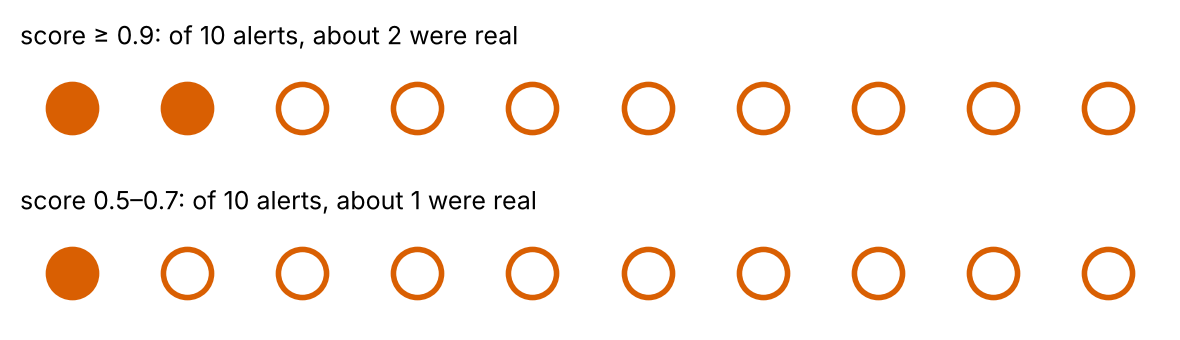

In [14]:
band_hi = df[df.ai_score >= 0.9]
band_lo = df[(df.ai_score >= 0.5) & (df.ai_score < 0.7)]

real_per_10_hi = int(round(band_hi["confirmed_fault"].mean() * 10))   # TODO: of 10 alerts with score >= 0.9, about how many were real faults? (round to a whole number)
real_per_10_lo = int(round(band_lo["confirmed_fault"].mean() * 10))   # TODO: same for scores 0.5-0.7

if ready(real_per_10_hi, real_per_10_lo):
    print(f"score >= 0.9: {band_hi.confirmed_fault.sum()} real of {len(band_hi)} alerts | score 0.5-0.7: {band_lo.confirmed_fault.sum()} real of {len(band_lo)} alerts")
    fig, ax = plt.subplots(2, 1, figsize=(6, 1.8))
    for a_, k, lab in zip(ax, [real_per_10_hi, real_per_10_lo], ["score ≥ 0.9", "score 0.5–0.7"]):
        for i in range(10): a_.scatter(i, 0, s=300, color=ACCENT if i < k else "white", edgecolors=ACCENT, linewidths=2)
        a_.axis("off"); a_.set_title(f"{lab}: of 10 alerts, about {k} were real", loc="left", fontsize=9)
    plt.tight_layout(); plt.show()

**✏️ Your answer (Part 7):** (a) Why does a red dot at every alert make Ravi's team **more** likely to miss the frozen H2 sensor? Use the words *salience* and *inattentional blindness*. (b) Rewrite vendor statement 6 using frequency framing.

*Your answer:*

**(a)** Bright red is the most **salient** thing on the chart, so it captures attention before anything else, and the dashboard spends that salience on 159 alerts of which 143 are harmless defrost readings. A viewer whose task has become "check the red dots" suffers **inattentional blindness** for anything that is not red: the frozen FZ-H2 sensor has *no* dot at all (its scores are under 0.1) and it is a flat grey line at −18 °C, the least salient shape possible. So the red dots do not just fail to mark the fault; they actively pull the eye away from it, and "no red" is read as "nothing wrong". Grading the emphasis by confidence and highlighting the flat *span* returns the salience to where the evidence is.

**(b)** Rewrite of statement 6: "A score is not a probability. Of the 37 alerts ColdSense scored 0.9 or higher, only 8 were real faults: **about 2 in every 10**, not 9 in 10. Of the 55 alerts scored 0.5–0.7, 6 were real: **about 1 in 10**." (The 0.7–0.9 band is even worse, 2 real out of 67, so the score is not even reliably ordered.)

---
## Part 8 · Standard deviation vs standard error (vendor statement 8)

The vendor judged a new FZ-B1 reading of **−15.9 °C at 14:00** against the 14:00 baseline.

In [15]:
base = df[(df.freezer_id == "FZ-B1") & (df.hour == 14) & (df.confirmed_fault == 0)]["temp_c"]
mu, sd, n = base.mean(), base.std(), len(base)
new_reading = -15.9

se = sd / np.sqrt(n)        # TODO: standard error of the baseline mean
z_sd = (new_reading - mu) / sd      # TODO: (new_reading - mu) / sd
z_se = (new_reading - mu) / se      # TODO: (new_reading - mu) / se

if ready(se, z_sd, z_se):
    print(f"baseline: mean {mu:.2f} °C, SD {sd:.2f}, n = {n}, SE = {se:.3f}")
    print(f"z using SD = {z_sd:.1f} | z using SE = {z_se:.1f}")

correct_z = 'SD'   # TODO: 'SD' or 'SE' - which one should be used to judge a single new reading?

baseline: mean -17.31 °C, SD 0.61, n = 42, SE = 0.094
z using SD = 2.3 | z using SE = 15.0


**✏️ Your answer (Part 8):** In one sentence each, say what the SD and the SE describe, and rewrite vendor statement 8.

*Your answer:*

The **SD** (0.61 °C here) describes how much *individual readings* vary around the mean. The **SE** (0.09 °C = SD/√42) describes how precisely we know the *mean itself*, and it shrinks as we collect more readings even though freezers do not become any steadier.

A single new reading must be compared with the spread of single readings, so the SD is the right yardstick. Rewrite of statement 8: "A new FZ-B1 reading of −15.9 °C at 14:00 is about **2.3 standard deviations** above the 14:00 baseline of −17.3 °C (n = 42 normal readings). That is unusual and worth checking against the next readings and the door-open count, but it is a candidate, not a definite fault." The "15 standard errors" figure answers a different question (is the *average* different?) and would grow without limit just by adding more baseline data.

---
## Part 9 · Triage the vendor report

For each statement decide: **Accept** (correct as stated), **Correct** (useful, but the wording or number must change) or **Reject** (not supported). Then measure the report.

In [16]:
decisions = {
    1: "Correct",   # 97.9% accurate, so trustworthy
    2: "Reject",   # most faults happen around 2 am
    3: "Accept",   # all 10 compressor trips caught
    4: "Reject",   # FZ-H2 had no fault
    5: "Correct",   # -14 °C is abnormal at any time
    6: "Reject",   # score 0.92 = 92% chance
    7: "Reject",   # threshold 0.5 is best
    8: "Correct",   # 15 standard errors: definite fault
}

if all(v in ("Accept", "Correct", "Reject") for v in decisions.values()):
    accepted = sum(v == "Accept" for v in decisions.values())
    print(f"Statements accepted as written: {accepted}/{len(decisions)} ({accepted / len(decisions):.0%})")
    print(pd.Series(decisions).value_counts().to_string())
else:
    print("⚠ Fill in all eight decisions with 'Accept', 'Correct' or 'Reject'.")

Statements accepted as written: 1/8 (12%)
Reject     4
Correct    3
Accept     1


**✏️ Your answer (Part 9):** Sketch (in words or a quick drawing) the **anomaly review view** you would give Ravi's team instead of the vendor's red-dot dashboard. Name at least four parts: main view, context, queue, verification tools, evaluation.

*Your answer:*

Why these decisions: **1 Correct** (97.9% is computed correctly, but "so it can be trusted" must go: precision 0.10, recall 0.35) · **2 Reject** (zero faults at 2 am; those are defrost false alarms) · **3 Accept** (10 of 10 compressor trips were flagged) · **4 Reject** (FZ-H2's sensor was frozen for 14 h on 20 Aug) · **5 Correct** (−14 °C is abnormal in the afternoon, normal during defrost) · **6 Reject** (about 2 in 10, not 92%) · **7 Reject** (0.30 is cheaper, and no threshold fixes the misses) · **8 Correct** (2.3 SD: unusual, not definite). Only 1 of 8 statements survives as written.

**Anomaly review view for Ravi's team**

1. **Main view: small multiples, one temperature line per freezer** on a shared time axis, drawn in grey. Alerts use *graded* emphasis (strong ≥ 0.9, moderate 0.7–0.9, outline 0.5–0.7, nothing below), never uniform red. Collective anomalies are drawn as a **shaded span**, not as points.
2. **Context layer:** behind each line, the expected band for that freezer at that hour of day (hourly median ± 4 MAD), with the 02:00–04:00 **defrost window shaded and labelled** so a normal defrost rise never looks alarming. Linked strips below show `door_opens`, `compressor_kw` and the raw `ai_score` as its own line (look at the score, don't only threshold it).
3. **Review queue:** a ranked list of *candidates* beside the chart, sorted by evidence rather than by time: context z-score, flat-line duration, then ColdSense score. Each row states the anomaly type (point / contextual / collective), the reason in words ("−14.6 °C at 15:00, usual −17.5 °C") and a frequency statement ("about 2 in 10 alerts like this were real"). Clicking a row zooms the main view to it.
4. **Verification tools:** brushing a time range to compare with the same hours on previous days and with the other freezers in the store; a toggle between the global baseline and the per-hour baseline; a rolling-SD "stuck sensor" check; a threshold slider that shows call-outs and missed faults live.
5. **Evaluation and feedback panel:** the technician records the outcome of each visit (confirmed / false alarm / not inspected), and the panel keeps running **precision and recall by fault type**, the confusion matrix and cost at the current threshold. Accuracy is not shown as a headline number.

---
## Reflection

Answer in 2–4 sentences each. There are no right-or-wrong answers here; we are looking for honest thinking about *your own* process.

**1. Automation bias.** Before you checked anything, which vendor statement did you find most convincing? Was it the number, the confident tone, or the red dots? Would you have caught the problem without the maintenance log?

*Your reflection:*

Before checking, statement 1 was the most convincing to me. "97.9% accurate" is a precise number, it is high, and it is stated as a conclusion ("so its alerts can be trusted"), which made it feel already verified. I could have found the base-rate problem without the maintenance log, since anyone can see that faults are rare, but I could not have known that 143 of the 159 alerts were false or that the frozen sensor was missed at all: without ground truth the red dots would have looked like the detector working.

**2. Who sets the threshold?** The threshold decides how many night call-outs happen and how many freezers spoil. Who at FreshKart should own that choice, and what information should the dashboard show them?

*Your reflection:*

The threshold is a business trade-off between technician time and spoiled stock, so it should be owned by Ravi as cold-chain lead, with input from the technicians and whoever carries the stock-loss cost, not by the vendor's default. The dashboard should show him the consequences in his own units: expected call-outs per week, expected missed faults by fault type, and the total cost curve at each threshold, along with the precision–recall curve. It should also show which fault types no threshold can reach, so that he does not believe the slider solves everything.

**3. Missing ground truth.** You had a maintenance log. In real life, faults nobody inspected never get a label. How would that change your precision and recall numbers, and how could the review workflow reduce the problem?

*Your reflection:*

If only alerted readings are inspected, the labels are biased: precision can still be estimated, because every alert gets a visit, but recall would look much better than it is, since missed faults like the frozen sensor are never visited and so never counted. Our recall of 0.35 exists only because the log covered faults the AI did not flag. The workflow can reduce this by inspecting a small random sample of non-alerted hours, running independent checks (the hourly-context baseline, the rolling-SD test) alongside the AI, recording "not inspected" separately from "normal", and feeding late discoveries such as spoiled stock back into the log as labels.

**4. Designing against over-trust.** Name one design change (encoding, interaction, wording) that would make technicians *check* an alert rather than simply obey or ignore it.

*Your reflection:*

I would replace the uniform red dot with graded emphasis plus a one-line reason and a frequency statement on each alert, for example "−13.4 °C at 02:00, inside the normal defrost band; about 2 in 10 alerts like this were real". Showing the expected band for that hour behind the reading lets a technician judge the alert in seconds. Asking them to record what they found closes the loop, so the alert becomes a claim to check, not an order to follow or a noise to mute.